# Semana 8 - Segmentación de clientes con K-Means
## Aprendizaje no supervisado

**Alumno:** Juan Pablo Monllor

**Problema:** a partir del comportamiento de compra y de uso del sitio, descubrir cuántos grupos de clientes existen, sin usar etiquetas previas.

**Modelo:** K-Means. El valor de k se elige con el método del codo, probando de 2 a 6 grupos.

## 1. Datos

**Dataset:** `dataset_segmentacion_clientes.csv`, provisto por la cátedra en el campus. Contiene 700 clientes con cinco variables de comportamiento de compra y de uso del sitio, más dos columnas de ruido.

In [7]:
# Importamos las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargamos el dataset
df = pd.read_csv("../datasets/dataset_segmentacion_clientes.csv")

# Mostramos las primeras filas
df.head()

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


In [8]:
# Dimensiones, valores faltantes y duplicados
print("Dimensiones del dataset:", df.shape)
print("Valores faltantes:", df.isnull().sum().sum())
print("Filas duplicadas:", df.duplicated().sum())

# Resumen estadístico de cada columna
df.describe().round(2)

Dimensiones del dataset: (700, 7)
Valores faltantes: 0
Filas duplicadas: 0


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
count,700.00,700.00,700.00,700.00,700.00,700.00,700.00
mean,5.88,248.17,16.78,0.43,0.34,0.02,-0.01
std,4.47,154.90,12.91,0.43,0.36,1.01,1.68
min,0.10,86.99,3.16,0.00,0.00,-3.57,-2.99
25%,2.28,90.77,6.60,0.00,0.00,-0.65,-1.42
50%,4.13,180.22,9.97,0.30,0.17,0.08,0.01
75%,11.21,449.72,34.34,1.00,0.80,0.73,1.41
max,14.60,452.97,38.35,1.00,0.80,2.86,3.00


## 2. Selección de variables

El dataset trae 7 columnas, pero la consigna describe solo 5 variables de comportamiento del cliente. Las columnas `noise_gauss` y `noise_uniform` son ruido: valores aleatorios centrados en 0 que no representan ninguna característica real del cliente. Si las dejamos, K-Means las tendría en cuenta al medir distancias y podría armar grupos peores. Por eso trabajamos solo con las 5 variables de la consigna.

In [9]:
# Nos quedamos solo con las 5 variables de comportamiento del cliente
variables = ["purchase_freq_month", "avg_basket_usd", "time_on_site_min",
             "discount_sensitivity", "returns_rate"]

X = df[variables]

print("Dimensiones con las variables elegidas:", X.shape)
X.head()

Dimensiones con las variables elegidas: (700, 5)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.152508,181.300834,33.564036,1.000000,0.800000
1,12.053451,178.637272,35.432081,0.784974,0.000000
2,2.203006,450.185298,7.030757,0.898297,0.000000
3,4.233314,89.006342,10.834453,0.000000,0.800000
4,1.716799,449.773982,7.254548,0.000000,0.003279


## 3. Escalado de las variables

Las variables tienen escalas muy distintas: el ticket promedio va de 87 a 453 USD, mientras que la sensibilidad a descuentos va de 0 a 1. K-Means agrupa según la distancia entre clientes, así que sin escalar el ticket dominaría todo y las demás variables casi no contarían. Con StandardScaler cada variable queda con media 0 y desvío 1, y todas pesan lo mismo.

Como K-Means no usa etiquetas, no hace falta separar en entrenamiento y prueba: el escalado se ajusta con todos los datos.

In [10]:
from sklearn.preprocessing import StandardScaler

# Escalamos las 5 variables
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X)

# Comprobamos que cada variable quedó con media 0 y desvío 1
pd.DataFrame(X_escalado, columns=variables).describe().round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
count,700.00,700.00,700.00,700.00,700.00
mean,-0.00,-0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00
min,-1.29,-1.04,-1.06,-0.99,-0.95
25%,-0.81,-1.02,-0.79,-0.99,-0.95
50%,-0.39,-0.44,-0.53,-0.30,-0.48
75%,1.20,1.30,1.36,1.33,1.30
max,1.95,1.32,1.67,1.33,1.30


## 4. Elección de k: método del codo

Entrenamos K-Means con k de 2 a 6 y guardamos la inercia de cada modelo (la suma de las distancias al cuadrado de cada cliente al centro de su grupo). La inercia siempre baja al agregar grupos, así que buscamos el "codo": el punto a partir del cual sumar un grupo más ya no la reduce de forma importante.

k = 2  ->  inercia = 2088.9
k = 3  ->  inercia = 1408.7
k = 4  ->  inercia = 1173.4
k = 5  ->  inercia = 997.7
k = 6  ->  inercia = 762.5


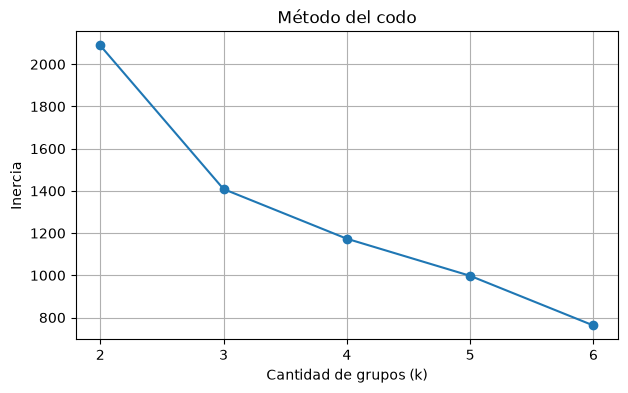

In [11]:
from sklearn.cluster import KMeans

valores_k = range(2, 7)
inercias = []

for k in valores_k:
    kmeans = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42)
    kmeans.fit(X_escalado)
    inercias.append(kmeans.inertia_)
    print(f"k = {k}  ->  inercia = {kmeans.inertia_:.1f}")

# Gráfico del codo
plt.figure(figsize=(7, 4))
plt.plot(valores_k, inercias, marker="o")
plt.xlabel("Cantidad de grupos (k)")
plt.ylabel("Inercia")
plt.title("Método del codo")
plt.xticks(valores_k)
plt.grid(True)
plt.show()

**Elección:** el codo está en k = 3. De 2 a 3 grupos la inercia baja unos 680 puntos; de 3 a 4 baja solo unos 235, y a partir de ahí sigue bajando de a poco. Agregar más de 3 grupos no mejora de forma importante la agrupación.

## 5. Modelo final con k = 3

In [12]:
# Entrenamos el modelo final con 3 grupos
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=10, random_state=42)
kmeans.fit(X_escalado)

# Agregamos a cada cliente el grupo que le asignó el modelo
df["grupo"] = kmeans.labels_

# Cantidad de clientes en cada grupo
print("Clientes por grupo:")
print(df["grupo"].value_counts().sort_index())

# Centroides llevados a las unidades originales para poder interpretarlos
centroides = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                          columns=variables)
centroides.round(2)

Clientes por grupo:
grupo
0    230
1    250
2    220
Name: count, dtype: int64


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate
0,11.96,180.00,35.02,0.54,0.33
1,1.85,450.12,5.97,0.36,0.38
2,4.09,89.96,10.00,0.38,0.30


## 6. Perfiles de clientes

Comparando los centroides de cada grupo, variable por variable:

| Grupo | Clientes | Frecuencia | Ticket | Tiempo en sitio | Sens. a descuentos | Perfil |
|---|---|---|---|---|---|---|
| 0 | 230 | Alta (12/mes) | Medio (180 USD) | Alto (35 min) | Más alta (0,54) | Frecuentes |
| 1 | 250 | Baja (2/mes) | Alto (450 USD) | Bajo (6 min) | Media (0,36) | Premium esporádicos |
| 2 | 220 | Media (4/mes) | Bajo (90 USD) | Bajo (10 min) | Media (0,38) | Ocasionales de ticket bajo |

- **Grupo 0 - Frecuentes:** compran casi tres veces por semana, pasan mucho tiempo en el sitio y son los más sensibles a los descuentos. Foco: promociones y programas de fidelización.
- **Grupo 1 - Premium esporádicos:** compran poco pero con el ticket más alto, y entran al sitio por poco tiempo, como si ya supieran qué buscan. Foco: productos premium y upselling.
- **Grupo 2 - Ocasionales de ticket bajo:** compran cada tanto, gastan poco y exploran poco. Foco: estrategias para aumentar la frecuencia y el ticket.

**Observación:** la tasa de devoluciones es muy parecida en los tres grupos (entre 0,30 y 0,38), así que en estos datos no aparece un grupo que se diferencie por devolver más o menos.

## 7. Conclusión

K-Means permitió encontrar tres segmentos de clientes sin usar etiquetas previas. Antes de agrupar fue clave descartar las dos columnas de ruido y escalar las variables, porque sin escalar el ticket promedio, por sus valores grandes, habría dominado las distancias.

El método del codo indicó que k = 3 es un valor razonable: a partir de ahí, agregar grupos casi no mejora la inercia. Los tres perfiles encontrados (frecuentes, premium esporádicos y ocasionales de ticket bajo) se diferencian sobre todo por la frecuencia de compra, el ticket y el tiempo en el sitio, y cada uno sugiere una estrategia comercial distinta. La tasa de devoluciones, en cambio, no distingue a los grupos en este dataset.